In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

In [2]:
import pandas as pd
import time
import numpy as np
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor
import torch
import torch.nn as nn
from src.model.ESN import ESNRegressor

In [3]:
df = pd.read_pickle('data/lorenz_data.pkl')
df.drop(columns=["dt_min", "t_max"], inplace=True)
df.head()

,t,x,y,z
0,0.000,-7.906697,-14.129764,-16.306456
1,0.001,-7.968928,-14.465952,-16.151253
2,0.002,-8.033898,-14.803325,-15.992904
3,0.003,-8.101592,-15.141956,-15.831328
4,0.004,-8.171996,-15.481917,-15.666437


In [4]:
STRIDE = 100
df_strides = df[ ::STRIDE ].reset_index(drop=True)

In [5]:
df_strides.head()

,t,x,y,z
0,0.0,-7.906697,-14.129764,-16.306456
1,0.1,-24.672225,-42.914606,35.172661
2,0.2,-10.285805,23.156058,48.685025
3,0.3,10.837283,18.620737,42.387750
4,0.4,8.634182,0.248069,41.103149


In [6]:
df_strides[100:105]

,t,x,y,z
100,10.0,5.621907,7.848892,21.957250
101,10.1,8.172017,11.064759,22.585364
102,10.2,10.855023,12.750135,27.747833
103,10.3,10.888821,8.897440,32.231589
104,10.4,7.908417,4.722127,30.117574


In [7]:
df_strides = df_strides[100:].reset_index(drop=True)
df_strides.head()

,t,x,y,z
0,10.0,5.621907,7.848892,21.957250
1,10.1,8.172017,11.064759,22.585364
2,10.2,10.855023,12.750135,27.747833
3,10.3,10.888821,8.897440,32.231589
4,10.4,7.908417,4.722127,30.117574


In [8]:
rng = np.random.default_rng(0)
#device = 'cpu' # torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
data = df_strides.to_numpy(dtype=np.float32)


In [9]:
# === Minimal 20-step teacher-forced training with ESNRegressor.forward_step ===
# - Uses your ESNRegressor(warmup, forward_step, Wout)
# - Windows: warm=20, x=20 (y is next-step target for each x_t)
# - No skorch, pure PyTorch DataLoader + loops

import os, math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# ---------------------------------------------------------------------
# 0) Imports from your project (assumes ESN.py, data.py, util.py exist)
# ---------------------------------------------------------------------
from src.model.ESN import ESNRegressor
from src.data import LorenzStartsDataset
from src.util import compute_stats

# ---------------------------------------------------------------------
# 1) Config
# ---------------------------------------------------------------------
WARM       = 10           # warmup window length
XLEN       = 100           # teacher-forced window length
YLEN       = 10           # prediction window length
BATCH_SIZE = 64
LR         = 1e-3
EPOCHS     = 3
TRAIN_SPLIT= 0.70
SEED       = 42

series = df_strides[["x", "y", "z"]].to_numpy(dtype=np.float32) 
series = series[:10000]    # (T, 3)
#D = series.shape[1]        # 3
#windows = build_windows(dev_series, warm_length=WARM, x_length=XLEN)   # (N, W+X+1, 3) view

# Use MPS on Apple Silicon if available, else CUDA if available, else CPU
def pick_device():
    if torch.backends.mps.is_available():
        return "mps"
    if torch.cuda.is_available():
        return "cuda"
    return "cpu"

device = pick_device()
torch.manual_seed(SEED)
np.random.seed(SEED)

# Optional: keep BLAS threads modest for notebook responsiveness
#os.environ.setdefault("OMP_NUM_THREADS", "1")
#os.environ.setdefault("MKL_NUM_THREADS", "1")

# ---------------------------------------------------------------------
# 2) Provide/Load a raw series (T, D). If you already have `series`, skip the fallback.
# ---------------------------------------------------------------------
try:
    series  # already defined upstream
except NameError:
    # Fallback synthetic so the cell runs even without your data
    rng = np.random.default_rng(0)
    T, D = 20000, 3
    series = rng.normal(size=(T, D)).astype(np.float32)
    for t in range(1, T):
        series[t] = 0.7 * series[t-1] + 0.3 * series[t]

assert isinstance(series, np.ndarray) and series.ndim == 2
T, D = series.shape

# ---------------------------------------------------------------------
# 3) Build chronological window starts and train/valid split (no leakage)
# ---------------------------------------------------------------------
total = WARM + XLEN + 1  # +1 so each x_t maps to next-step y_t
N = T - total
if N <= 0:
    raise ValueError(f"Series too short: need > {total}, got {T}")

starts = np.arange(N, dtype=np.int64)
n_train = int(TRAIN_SPLIT * N)
train_starts = starts[:n_train]
valid_starts = starts[n_train:]

# Train-only standardization stats (cover all training windows)
train_tail  = (train_starts[-1] + total) if len(train_starts) else 0
train_slice = series[:max(train_tail, int(TRAIN_SPLIT * T))]
mean, std   = compute_stats(train_slice)

# Datasets (return: warm:(B,20,D), x:(B,20,D), y:(B,20,D) where y is next-step)
train_ds = LorenzStartsDataset(series, train_starts, warm_length=WARM, x_length=XLEN, y_length=YLEN,
                               standardize=True, mean=mean, std=std)
valid_ds = LorenzStartsDataset(series, valid_starts, warm_length=WARM, x_length=XLEN, y_length=YLEN,
                               standardize=True, mean=mean, std=std)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE,        shuffle=False, num_workers=0)

print(f"Device: {device} | Train windows: {len(train_ds)} | Valid windows: {len(valid_ds)}")
print("Shapes -> warm:", train_ds[0][0].shape, "x:", train_ds[0][1].shape, "y:", train_ds[0][2].shape)

# ---------------------------------------------------------------------
# 4) Init ESNRegressor (trainable readout; reservoir typically fixed)
# ---------------------------------------------------------------------
esn = ESNRegressor(
    input_size=D,
    output_size=D,         # predict next D-dim vector
    reservoir_size=1000,    # good starting point; scale after it works
    leak=0.9,
    spectral_radius=1.0,
    input_scale=0.9,
    bias_scale=0.0,
    sparsity=0.05,
    activation='tanh',
    seed=SEED,
).to(device)

# Only train parameters that require grad (commonly just the readout layer)
params = [p for p in esn.parameters() if p.requires_grad]
opt    = torch.optim.Adam(params, lr=LR)
mse    = nn.MSELoss(reduction='mean')

# ---------------------------------------------------------------------
# 5) Teacher-forced next-step prediction using forward_step
# ---------------------------------------------------------------------
def predict_teacher_via_step(esn, warm, x):
    """
    warm: (B, 20, D), x: (B, 20, D)
    Steps:
      1) r = esn.warmup(warm)[0]  -> reservoir state after warmup
      2) for t in 0..19:
           r = esn.forward_step(r, x_t)
           y_t = esn.Wout(r)   # next-step prediction
    Returns y_pred: (B, 20, D)
    """
    # Warmup to get reservoir state; ignore last input (teacher provides x_t)
    r, _last_in = esn.warmup(warm)          # r: (B, N_res)
    B, X, _ = x.shape
    outs = []
    for t in range(X):
        x_t = x[:, t, :]                    # (B, D)
        r   = esn.forward_step(r, x_t)      # update state with teacher input
        y_t = esn.Wout(r)                   # project state -> output
        outs.append(y_t.unsqueeze(1))
    return torch.cat(outs, dim=1)           # (B, X, D)

# ---------------------------------------------------------------------
# 6) Train / Eval loops
# ---------------------------------------------------------------------
def train_one_epoch():
    esn.train()
    tot, n = 0.0, 0
    for warm, x, y in train_loader:
        warm, x, y = warm.to(device), x.to(device), y.to(device)
        y_pred = predict_teacher_via_step(esn, warm, x)
        loss   = mse(y_pred, y)

        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(esn.parameters(), 1.0)
        opt.step()

        bs = warm.size(0)
        tot += loss.item() * bs; n += bs
    return tot / max(1, n)

@torch.no_grad()
def eval_one_epoch():
    esn.eval()
    tot, n = 0.0, 0
    for warm, x, y in valid_loader:
        warm, x, y = warm.to(device), x.to(device), y.to(device)
        y_pred = predict_teacher_via_step(esn, warm, x)
        loss   = mse(y_pred, y)
        bs = warm.size(0)
        tot += loss.item() * bs; n += bs
    return tot / max(1, n)

Device: mps | Train windows: 6922 | Valid windows: 2967
Shapes -> warm: torch.Size([10, 3]) x: torch.Size([100, 3]) y: torch.Size([100, 3])


# Dataset Formatting Complete

In [10]:
# ---------------------------------------------------------------------
# 7) Run
# ---------------------------------------------------------------------
for ep in range(1, EPOCHS + 1):
    tr = train_one_epoch()
    va = eval_one_epoch()
    print(f"ep {ep:02d} | train_mse={tr:.6f} | valid_mse={va:.6f}")

ep 01 | train_mse=0.089517 | valid_mse=0.004891
ep 02 | train_mse=0.002816 | valid_mse=0.001918
ep 03 | train_mse=0.001403 | valid_mse=0.001219


10-step rollout MSE (std): 0.424214
per-dim MSE: [0.207648 0.410434 0.654559]
R² per dim : [ 0.169192 -0.370219  0.072242]


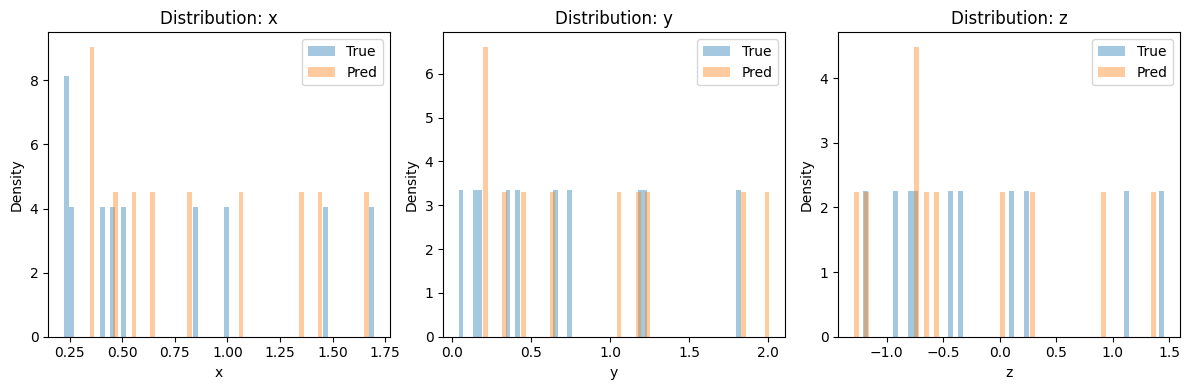

In [11]:
from src.util import report_rollout_metrics

report = report_rollout_metrics(esn, valid_ds, WARM, XLEN, K=10, device=device)

# Train a Model using Ridge Regression

In [12]:
import gc, torch
try:
    torch.mps.empty_cache()   # harmless if not on Mac/MPS
except Exception:
    pass
gc.collect()

# --- 1) Build a CPU-only ESN for the ridge pipeline (float32) ---
RIDGE_DEVICE = "cpu"  # <- keep ridge entirely on CPU

esn_RR = ESNRegressor(
    input_size=D,
    output_size=D,
    reservoir_size=700,
    leak=0.9,
    spectral_radius=1.0,
    input_scale=0.9,
    bias_scale=0.0,
    sparsity=0.05,
    activation='tanh',
    seed=SEED,
).to(torch.float32).to(RIDGE_DEVICE) 


import torch
import torch.nn as nn

# Running mean/var in float32 (Welford, batched)
class _RunningStats:
    def __init__(self, d: int):
        self.n = 0
        self.mean = torch.zeros(d, dtype=torch.float32)
        self.M2   = torch.zeros(d, dtype=torch.float32)

    def update(self, X: torch.Tensor):  # X: (N,d) CPU float32
        if X.numel() == 0:
            return
        n = X.shape[0]
        self.n += n
        mu_b  = X.mean(dim=0)
        delta = mu_b - self.mean
        self.mean += delta * (n / max(1, self.n))
        xc = X - self.mean
        self.M2 += (xc * xc).sum(dim=0)

    def finalize(self, eps: float = 1e-8):
        var = self.M2 / max(1, (self.n - 1))
        std = torch.sqrt(var + eps)
        return self.mean, std  # float32

@torch.inference_mode()
def _pass_stats_R_Y(esn, loader, L: int, device: str):
    """Compute mu/std for reservoir R (M) and multi-horizon Y (L*D) in float32."""
    esn.eval()
    M = esn.Wout.in_features
    D = esn.Wout.out_features
    rstats = _RunningStats(M)
    ystats = _RunningStats(L * D)

    for warm, x, y in loader:
        warm, x, y = warm.to(device), x.to(device), y.to(device)
        r, _ = esn.warmup(warm)                     # (B, M)
        B, X, D_chk = x.shape
        assert D_chk == D
        max_t = X - L + 1
        if max_t <= 0:
            continue
        for t in range(X):
            r = esn.forward_step(r, x[:, t, :])
            if t >= max_t:
                continue
            R = r.detach().to("cpu", dtype=torch.float32)                           # (B, M)
            Y = y[:, t:t+L, :].reshape(B, L * D).detach().to("cpu", dtype=torch.float32)  # (B, L*D)
            rstats.update(R)
            ystats.update(Y)

    mu_R, std_R = rstats.finalize()
    mu_Y, std_Y = ystats.finalize()
    return mu_R, std_R, mu_Y, std_Y

@torch.inference_mode()
def ridge_fit_multi_horizon_zonly(esn, train_loader, L: int, alpha: float, device: str):
    """
    Fit Θ in STANDARDIZED (z-scored) space (all float32):
      ([Rz|1]^T [Rz|1] + αI) Θz = [Rz|1]^T Yz
    Returns: Theta_z (float32, (M+1, L*D)), stats=(mu_R,std_R,mu_Y,std_Y) all float32.
    """
    assert isinstance(esn.Wout, nn.Linear)
    M = esn.Wout.in_features
    D = esn.Wout.out_features

    mu_R, std_R, mu_Y, std_Y = _pass_stats_R_Y(esn, train_loader, L, device)

    G = torch.zeros(M + 1, M + 1, dtype=torch.float32)        # normal equations
    H = torch.zeros(M + 1, L * D, dtype=torch.float32)
    ones_cache = None

    for warm, x, y in train_loader:
        warm, x, y = warm.to(device), x.to(device), y.to(device)
        r, _ = esn.warmup(warm)
        B, X, _ = x.shape
        max_t = X - L + 1
        if max_t <= 0:
            continue

        for t in range(X):
            r = esn.forward_step(r, x[:, t, :])
            if t >= max_t:
                continue

            R = r.detach().to("cpu", dtype=torch.float32)                           # (B, M)
            Y = y[:, t:t+L, :].reshape(B, L * D).detach().to("cpu", dtype=torch.float32)  # (B, L*D)
            Rz = (R - mu_R) / std_R
            Yz = (Y - mu_Y) / std_Y

            if (ones_cache is None) or (ones_cache.size(0) < B):
                ones_cache = torch.ones(B, 1, dtype=torch.float32)
            R_aug = torch.cat([Rz, ones_cache[:B]], dim=1)                          # (B, M+1)

            G += R_aug.T @ R_aug
            H += R_aug.T @ Yz

    G = G + (torch.eye(M + 1, dtype=torch.float32) * float(alpha))
    Theta_z = torch.linalg.solve(G, H)                                              # (M+1, L*D)
    return Theta_z, (mu_R, std_R, mu_Y, std_Y)
@torch.inference_mode()
def eval_multi_horizon_mse_zonly(esn, loader, Theta_z, L: int, stats, device: str):
    """
    Return average MSE in STANDARDIZED space:
      compare Yz_hat vs Yz (both z-scored). No inverse scaling anywhere.
    """
    esn.eval()
    mu_R, std_R, mu_Y, std_Y = stats
    M = esn.Wout.in_features
    D = esn.Wout.out_features
    assert Theta_z.dtype == torch.float32 and Theta_z.shape == (M + 1, L * D)

    sse = 0.0
    n = 0
    for warm, x, y in loader:
        warm, x, y = warm.to(device), x.to(device), y.to(device)
        r, _ = esn.warmup(warm)
        B, X, _ = x.shape
        max_t = X - L + 1
        if max_t <= 0:
            continue

        for t in range(X):
            r = esn.forward_step(r, x[:, t, :])
            if t >= max_t:
                continue

            R = r.detach().to("cpu", dtype=torch.float32)                           # (B, M)
            Y = y[:, t:t+L, :].reshape(B, L * D).detach().to("cpu", dtype=torch.float32)  # (B, L*D)

            Rz     = (R - mu_R) / std_R
            Yz     = (Y - mu_Y) / std_Y                         # standardized target
            ones   = torch.ones(B, 1, dtype=torch.float32)
            Yz_hat = torch.cat([Rz, ones], dim=1) @ Theta_z     # standardized prediction

            diff = Yz_hat - Yz
            sse += float((diff * diff).sum())
            n   += int(diff.numel())

    return sse / max(1, n)  # standardized-space MSE


# ----------------- Usage -----------------
# LWIN must be <= XLEN (e.g., 5, 10, or 20). If XLEN=20 and you set LWIN=20,
# each window contributes exactly one training row; with LWIN=10 you get X-L+1 rows per window.
LWIN  = 10        # try 5–10 for more rows; can set to 20 if you prefer
ALPHA = 1e-2      # ridge regularization


Theta_z, stats = ridge_fit_multi_horizon_zonly(
    esn_RR,               # CPU ESN
    train_loader,         # batches will be moved to CPU inside function
    L=LWIN,
    alpha=ALPHA,
    device=RIDGE_DEVICE,  # <<< 'cpu'
)

tr_mse_z = eval_multi_horizon_mse_zonly(
    esn_RR, train_loader, Theta_z, L=LWIN, stats=stats, device=RIDGE_DEVICE
)
va_mse_z = eval_multi_horizon_mse_zonly(
    esn_RR, valid_loader, Theta_z, L=LWIN, stats=stats, device=RIDGE_DEVICE
)
print(f"[Z-space] multi-horizon ridge (L={LWIN}, alpha={ALPHA:g}) | "
      f"train_mse={tr_mse_z:.6f} | valid_mse={va_mse_z:.6f}")


[Z-space] multi-horizon ridge (L=10, alpha=0.01) | train_mse=6.399265 | valid_mse=8.736651


10-step rollout MSE (std): 0.746838
per-dim MSE: [0.679629 0.679053 0.881831]
R² per dim : [-1.719217 -1.266994 -0.249889]


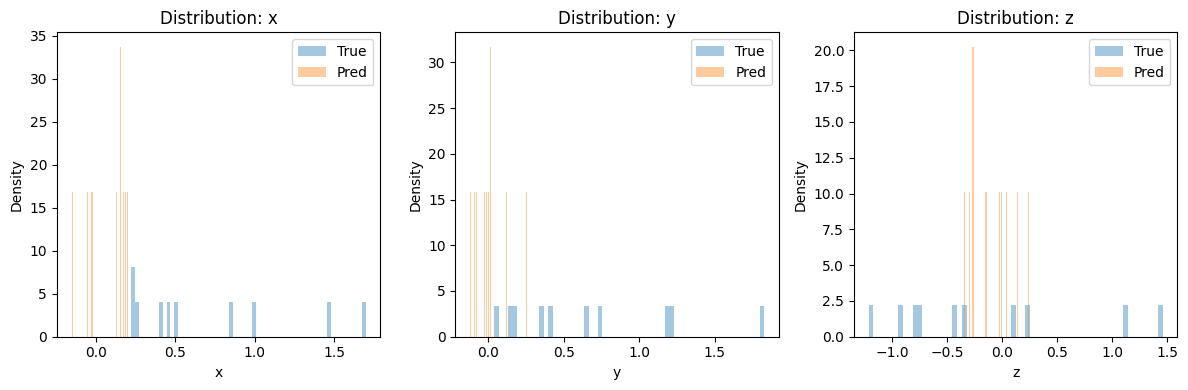

In [13]:
report = report_rollout_metrics(esn_RR, valid_ds, WARM, XLEN, K=10, device=RIDGE_DEVICE)

In [14]:
from typing import Optional, Dict, Any


@torch.inference_mode()
def rollout_autonomous_std(esn,
                           warm_std: torch.Tensor,
                           K: int,
                           readout_fn,
                           device: str = "cpu",
                           sync_x_std: Optional[torch.Tensor] = None):
    """
    Autonomous free-run in STANDARDIZED space.

    Args:
      esn:            trained ESN (not modified)
      warm_std:       (WARM,D) tensor, standardized; used for warmup
      K:              rollout horizon (# of free-run steps)
      readout_fn:     callable(r)->(B,D) returning STANDARDIZED predictions (e.g., from make_readout_std)
      device:         'cpu' / 'cuda' / 'mps'
      sync_x_std:     optional (XLEN,D) STANDARDIZED teacher sequence to sync reservoir
                      before free-run (recommended: your start window 'x' part)

    Returns:
      preds_std:      (K,D) NumPy array in STANDARDIZED space (float32)
    """
    esn.eval()
    warm_std = warm_std.to(device, torch.float32).unsqueeze(0)   # (1,W,D)
    r, _ = esn.warmup(warm_std)                                  # (1,M)

    if sync_x_std is not None:
        sync_x_std = sync_x_std.to(device, torch.float32).unsqueeze(0)  # (1,X,D)
        for t in range(sync_x_std.size(1)):
            r = esn.forward_step(r, sync_x_std[:, t, :])         # teacher-forced sync

    preds = []
    # bootstrap the loop with the current state
    x_next = readout_fn(r)                                       # (1,D) standardized
    for _ in range(int(K)):
        r = esn.forward_step(r, x_next)
        y_t = readout_fn(r)                                      # (1,D) standardized
        preds.append(y_t)
        x_next = y_t  
    return torch.cat(preds, dim=0).squeeze(1).detach().cpu().numpy().astype("float32")
    # shape (K,D)

(10000, 3) float32


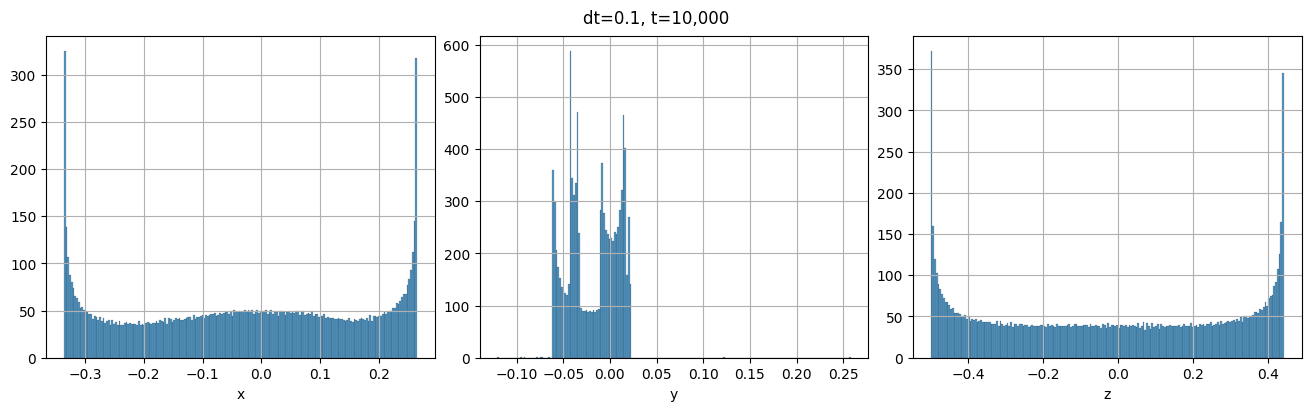

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
# Pick the same device your ESN is on (CPU is fine for long runs)
device = next(esn_RR.parameters()).device

# 1) Define a readout function (standardized)
def model_head_std(r: torch.Tensor) -> torch.Tensor:
    return esn_RR.Wout(r)  # (B, D), standardized

# 2) Choose a start window (recommended: warm + teacher forcing sync)
warm_std, x_std, y_std = valid_ds[0]  # (WARM,D), (XLEN,D), (XLEN,D)

# 3) Run autonomous rollout (STANDARDIZED output)
RUN = 10_000
pred_RUN = rollout_autonomous_std(
    esn_RR,
    warm_std=warm_std,
    K=RUN,
    readout_fn=model_head_std,   # <-- not None
    device=str(device),
    sync_x_std=x_std,            # teacher-force x before free-run (recommended)
)
print(pred_RUN.shape, pred_RUN.dtype)  # (10000, D) float32

cols = ["x", "y", "z"]
df_pred = pd.DataFrame(pred_RUN, columns=cols)
labels = {0: 'x', 1: 'y', 2: 'z'}
fig, axs = plt.subplots(1, 3, layout='constrained', figsize=(13, 4))
for i, arr in enumerate([df_pred['x'], df_pred['y'], df_pred['z']]):
    sns.histplot(arr, bins=200, ax=axs[i])
    axs[i].set_xlabel(f'{labels[i]}')
    axs[i].set_ylabel('')
    axs[i].grid(True)
fig.suptitle(f'dt={0.1}, t={10_000:,}')
plt.show()

In [16]:
# ================== Save / Load BOTH ESN (SGD) and Ridge Readout ==================
# Works with your ESNRegressor (has .warmup, .forward_step, .Wout and attrs below).
# All tensors are stored in float32 on CPU.

import torch
from typing import Optional, Dict, Any

# ---- small helper: extract ESN ctor params (adapt names if your class differs) ----
def _esn_config_from(esn) -> Dict[str, Any]:
    return dict(
        input_size      = int(getattr(esn, "input_size")),
        output_size     = int(getattr(esn, "output_size")),
        reservoir_size  = int(getattr(esn, "reservoir_size")),
        leak            = float(getattr(esn, "leak")),
        spectral_radius = float(getattr(esn, "spectral_radius")),
        input_scale     = float(getattr(esn, "input_scale")),
        bias_scale      = float(getattr(esn, "bias_scale")),
        sparsity        = float(getattr(esn, "sparsity")),
        activation      = str(getattr(esn, "activation")),
        seed            = int(getattr(esn, "seed", 0)),
    )

# ---- standardized ridge readout builder (Θ is ((M+1), L*D); pick step=0 for 1-step) ----
def make_readout_std(Theta, mu_R, std_R, D: int, step: int = 0):
    Theta = torch.as_tensor(Theta, dtype=torch.float32).contiguous()
    mu_R  = torch.as_tensor(mu_R, dtype=torch.float32).contiguous()
    std_R = torch.as_tensor(std_R, dtype=torch.float32).contiguous()
    start, end = step * D, (step + 1) * D
    Theta1 = Theta[:, start:end].contiguous()  # ((M+1), D)

    def _f(r: torch.Tensor) -> torch.Tensor:  # r: (B,M)
        dev, dt = r.device, r.dtype
        rz = (r - mu_R.to(dev, dt)) / std_R.to(dev, dt)
        ones = torch.ones(rz.size(0), 1, device=dev, dtype=dt)
        return torch.cat([rz, ones], dim=1) @ Theta1.to(dev, dt)  # standardized (B,D)
    return _f

# ---------------------------- SAVE ----------------------------
def save_esn_both(
    path: str,
    esn,                                  # SGD-trained ESN (contains Wout)
    ridge: Optional[Dict[str, torch.Tensor]] = None,  # {"Theta":..., "mu_R":..., "std_R":..., "mu_Y":..., "std_Y":...} (all std-space)
    meta: Optional[Dict[str, Any]] = None
):
    """
    Save ESN (state_dict + ctor config) and optional ridge readout to a single .pt file.
    """
    ckpt = {
        "esn_config": _esn_config_from(esn),
        "esn_state": {k: v.detach().to("cpu", torch.float32) for k, v in esn.state_dict().items()},
        "meta": meta or {},
    }
    if ridge is not None:
        ckpt["ridge"] = {
            "Theta":  ridge["Theta"].detach().to("cpu", torch.float32),
            "mu_R":   ridge["mu_R"].detach().to("cpu", torch.float32),
            "std_R":  ridge["std_R"].detach().to("cpu", torch.float32),
            # keep Y stats if you computed them (often ~0/1 if dataset already standardized)
            "mu_Y":   ridge.get("mu_Y", None),
            "std_Y":  ridge.get("std_Y", None),
            # any extras (alpha, L, etc.)
            "L":      int(ridge.get("L", 1)),
            "alpha":  float(ridge.get("alpha", 0.0)),
        }
    torch.save(ckpt, path)

# ---------------------------- LOAD ----------------------------
def load_esn_both(path: str, ESNClass, device: str = "cpu"):
    """
    Load both: returns (esn, heads, ckpt)
      - esn: ESNClass restored on device (SGD-trained weights inside)
      - heads: dict with:
          'sgd':   callable r -> y_std via esn.Wout
          'ridge': callable r -> y_std (if ridge present) using step-0 Θ
      - ckpt: raw checkpoint dict (includes ridge stats if present)
    """
    ckpt = torch.load(path, map_location="cpu")
    esn = ESNClass(**ckpt["esn_config"]).to(device)
    # ensure float32
    esn.load_state_dict({k: v.to(torch.float32) for k, v in ckpt["esn_state"].items()})

    def sgd_head(r: torch.Tensor) -> torch.Tensor:
        return esn.Wout(r)  # standardized if your data was standardized

    heads = {"sgd": sgd_head, "ridge": None}

    if "ridge" in ckpt:
        rd = ckpt["ridge"]
        D  = int(getattr(esn, "output_size"))
        ridge_head = make_readout_std(rd["Theta"], rd["mu_R"], rd["std_R"], D=D, step=0)
        heads["ridge"] = ridge_head

    return esn, heads, ckpt

# from ESN import ESNRegressor
# esn_loaded, heads, ckpt = load_esn_both("esn_both.pt", ESNRegressor, device="cpu")
# # Choose a head:
# head = heads["ridge"] if heads["ridge"] is not None else heads["sgd"]
# # Now head(r) returns standardized next-step predictions


In [17]:
ESN_DIR = "saved_models"
#   1) Save just the SGD model:
save_esn_both(f"{ESN_DIR}/esn_sgd.pt", esn, ridge=None, meta={"note":"SGD head"})
# mu_R, std_R, mu_Y, std_Y
#   2) Save SGD + ridge (Θ + stats):
ridge_pkg = {
    "Theta":  Theta_z.detach().to("cpu", torch.float32),
    "mu_R":   stats[0].detach().to("cpu", torch.float32),
    "std_R":  stats[1].detach().to("cpu", torch.float32),
    "mu_Y":   stats[2].detach().to("cpu", torch.float32),
    "std_Y":  stats[3].detach().to("cpu", torch.float32),
    "L":      int(LWIN),
    "alpha":  float(ALPHA),
}
save_esn_both(
    f"{ESN_DIR}/esn_ridge.pt", esn, ridge=ridge_pkg,
    meta={"dataset":"standardized", "note":"ridge head + SGD head"}
)